# Stage 1: MH065, 314-gene panel

Raw Xenium data → QC → normalisation → saved inputs → gene-set scoring → `cell_class_threshold` → Nhood enrichment.

Clusters 25 were removed after review, so the kept cells, clusters, `anno`, PCA and UMAP come from the saved object. A hand-applied label rule, in the parameters cell, is also used. Section 6 tests how much recalculating PCA changes the labels and Nhood z-scores.

## Parameters

In [1]:
SAMPLE = "MH065_314"

# Folders: set these before running
RAW_DATA_DIR = "/path/to/raw_xenium"  # one subfolder per sample, with cell_feature_matrix.h5 and cells.csv
SAVED_OBJECT_DIR = "/path/to/saved_objects"
LABEL_TABLE_DIR = "/path/to/label_tables"
OUTPUT_ROOT = "/path/to/stage1_output"

# Inputs (read only)
RAW_DIR = f"{RAW_DATA_DIR}/{SAMPLE}"
SAVED_OBJECT = f"{SAVED_OBJECT_DIR}/{SAMPLE}.h5ad"
COUNTS_CSV = f"{LABEL_TABLE_DIR}/{SAMPLE}.csv"

# Outputs
OUTPUT_DIR = f"{OUTPUT_ROOT}/{SAMPLE}"

# Seeds
GLOBAL_SEED = 36
NHOOD_SEED = 112233
PCA_SEED = 36  # used only by the robustness check

# QC
CROP = None
GENES_TO_REMOVE = []
MIN_COUNTS = 10
MIN_CELLS = 5

# Clustering
N_NEIGHBORS = 15
LEIDEN_RESOLUTION = 2.0
LEIDEN_KEY = f"leiden_{LEIDEN_RESOLUTION}"

# Clusters removed in the original analysis; the kept cells come from SAVED_OBJECT
CLUSTERS_REMOVED = ["25"]
REMOVAL_SHARE = 0.5  # robustness check: remove a recalculated cluster if this share of its cells were removed

# Gene-set scoring
SCORE_QUANTILE = 0.75
LABEL_KEY = "cell_class_threshold"

def apply_label_changes(labels, anno):
    # Hand-changed labels in the original: SMCs must agree with the cluster-based annotation
    mask = labels == "SMCs"
    labels.loc[mask] = anno.loc[mask].map({
        "vSMCs": "SMCs",        # keep as SMCs
        "CAFs_MYO": "CAFs_MYO"  # reassign to CAFs_MYO
    }).fillna("SMCs")  # fallback used in the original
    return labels

# Nhood enrichment
RADIUS_UM = 50

# Marker genes for reviewing labels
label_markers = ["CD8A", "ITGAE", "ITGA1", "IL7R", "TCF7", "CD4", "GZMA", "GZMK", "GNLY", "NKG7", "MS4A1", "CD52", "CD19", "LAMP3", "CCL22", "CXCL13", "ICOS", "CD40LG", "FOXP3", "IKZF2", "CTLA4", "TIGIT", "MZB1", "IGHG1", "PLA2G2A", "IGF1", "PDPN", "CCL21", "FLT4", "CLEC9A", "IRF8", "IDO1", "CLEC10A", "CD1C", "C1QA", "SELENOP", "C1QC", "HLA-DMB", "CSF1R", "CD86", "HLA-DQA1", "PLVAP", "VWF", "FLT1", "CPA3", "KIT", "MS4A2", "ICAM1", "CCL19", "PDGFRA", "C7", "SCN7A", "ABCA6", "ABCA10", "CDH19", "CHL1", "NGFR", "CXCL14", "COL11A1", "PDGFC", "PDGFRB", "RGS5", "ACTA2", "CALD1", "OLR1", "SPP1", "GRN", "APOE", "MARCO", "POU2F3", "RGS13", "BMX", "AVIL", "MUC5B", "ONECUT2", "SLC4A4", "KRT19", "MUC1", "KRT8", "KRT7", "FXYD3", "INS", "GCG", "SST", "CFTR", "SLC4A4", "MUC6", "AMY2A", "CTRC", "PRSS1", "CUZD1", "REG3A", "REG3G", "REG1B"]

# Gene sets
gene_sets = {
    'Malignant cells': ['KRT19','KRT7','KRT5','FXYD3','MUC5AC'],
    'Ductal MUC5B': ['MUC5B','ONECUT2'],
    'Ductal' : ['CFTR','SLC4A4','MUC6'],
    'Acinar' : ['CPB1','CTRBR2','PRSS1'],
    'Acinar_REG+' : ['REG1B','REG3G','REG3A'],
    'Tuft' : ['AVIL','TRPM5','BMX','RGS13','SH2D6',"POU2F3"],
    'Endocrine': ['INS','GCG','SST'],
    'FRCs': {'PLA2G2A','PDPN','IGF1'},
    'TRCs': {"CCL19","PDGFRA","ICAM1"},
    'LECs': {'LYVE1','FLT4','PDPN','CCL21'},
    'Endothelial' : ['VWF','PLVAP','FLT1'],
    'SMCs' : ['RGS5','CSPG4','THBS1','ACTA2'],
    'Pericytes': ['PDGFRB','RGS5'],
    'Schwann': ['CDH19','CHL1','NGFR'],
    'CAFs_MYO': ['COL11A1','PDGFC'],
    'CAFs_CXCL14': ['COL11A1','CXCL14'],
    'CAFs_NRT' : ['PDGFRA','SCN7A','C7','ABCA6','ABCA10'],
    'NK': {'GNLY', 'NKG7','KLRC1'},
    'CD4 T cells': ['IL7R','CD4','TCF7'],
    'CD4 Treg' : {'FOXP3','IKZF2','CCR8'},
    'CD4 Tfh' : ['CD4','ICOS','CD40LG'],
    'CD8 T cells': ['CD8A','CD8B','GZMB','GZMA'],
    'CD8 TRM' : ['CD8A','CD8B','ITGAE','ITGA1'],
    'B cells': ['MS4A1','CD52','CD19'],
    'Plasma': ['MZB1'],
    'DC1' : ['CLEC9A','IRF8','IDO1'],
    'DC2' : ['CLEC10A','CD1C'],
    'Migratory DCs' : ['CCL22','LAMP3'],
    'Mast' :['CPA3','KIT','TPSAB1'],
    'TAMs_SPP1' : ['MARCO','GRN','APOE','SPP1'],
    'TAMs_OLR1' : ['OLR1','HBEGF'],
    'TAMs_C1QC' : ['C1QC','SELENOP','C1QA','F13A1','SLC40A1'],
    'TAMs_MHC' : ['CD86','HLA-DRB1','HLA-DRB5','CSF1R']
}

In [2]:
import importlib
import os
import random
import sys

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

import scanpy as sc
import squidpy as sq

from sklearn.metrics import adjusted_rand_score

np.random.seed(GLOBAL_SEED)
random.seed(GLOBAL_SEED)

assert os.path.exists(SAVED_OBJECT), f"Saved object not found: {SAVED_OBJECT}"
assert os.path.dirname(SAVED_OBJECT) != OUTPUT_DIR, "OUTPUT_DIR must not hold the saved object"
os.makedirs(OUTPUT_DIR, exist_ok=True)

packages = ["scanpy", "squidpy", "anndata", "numpy", "scipy", "pandas", "sklearn", "umap", "pynndescent",
            "numba", "leidenalg", "igraph", "h5py", "matplotlib", "seaborn"]
software = pd.DataFrame(
    [(p, getattr(importlib.import_module(p), "__version__", "unknown")) for p in packages],
    columns=["package", "version"],
)
software.to_csv(os.path.join(OUTPUT_DIR, "software_versions.tsv"), sep="\t", index=False)
print("python:", sys.version)
display(software)

~/miniconda3/envs/xenium.squidpy/lib/python3.9/site-packages/pandas/core/arrays/masked.py:61: UserWarning: Pandas requires version '1.3.6' or newer of 'bottleneck' (version '1.3.5' currently installed).
  from pandas.core import (
~/miniconda3/envs/xenium.squidpy/lib/python3.9/site-packages/dask/dataframe/_pyarrow_compat.py:15: FutureWarning: Minimal version of pyarrow will soon be increased to 14.0.1. You are using 13.0.0. Please consider upgrading.
  warnings.warn(
~/miniconda3/envs/xenium.squidpy/lib/python3.9/site-packages/numba/core/decorators.py:246: RuntimeWarning: nopython is set for njit and is ignored
  warnings.warn('nopython is set for njit and is ignored', RuntimeWarning)


python: 3.9.18 (main, Sep 11 2023, 13:41:44) 
[GCC 11.2.0]


,package,version
0,scanpy,1.9.5
1,squidpy,1.3.1
2,anndata,0.10.8
3,numpy,1.24.4
4,scipy,1.9.1
5,pandas,2.3.3
6,sklearn,1.3.2
7,umap,0.5.4
8,pynndescent,0.5.10
9,numba,0.60.0


## 1. Load raw data and QC

In [3]:
adata_all = sc.read_10x_h5(os.path.join(RAW_DIR, "cell_feature_matrix.h5"))
df = pd.read_csv(os.path.join(RAW_DIR, "cells.csv"))
df.set_index(adata_all.obs_names, inplace=True)
adata_all.obs = df.copy()
adata_all.obsm["spatial"] = adata_all.obs[["x_centroid", "y_centroid"]].copy().to_numpy()
print(f"Raw: {adata_all.n_obs} cells")

if CROP is not None:
    criteria = (
        (adata_all.obs["x_centroid"] >= CROP["x_min"]) & (adata_all.obs["x_centroid"] <= CROP["x_max"]) &
        (adata_all.obs["y_centroid"] >= CROP["y_min"]) & (adata_all.obs["y_centroid"] <= CROP["y_max"])
    )
    adata_all = adata_all[criteria, :].copy()
    print(f"After crop: {adata_all.n_obs} cells")

Raw: 159601 cells


~/miniconda3/envs/xenium.squidpy/lib/python3.9/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
~/miniconda3/envs/xenium.squidpy/lib/python3.9/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
~/miniconda3/envs/xenium.squidpy/lib/python3.9/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
~/miniconda3/envs/xenium.squidpy/lib/python3.9/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be

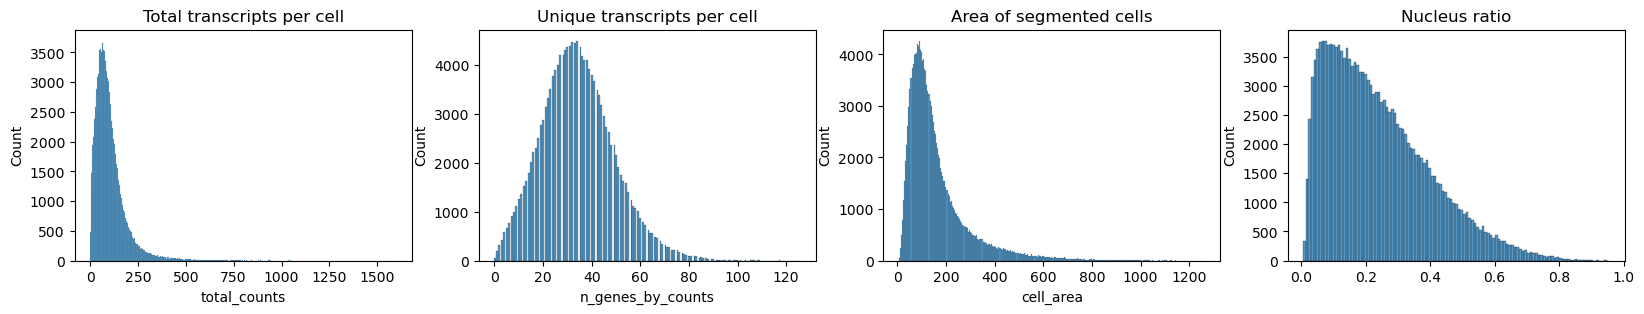

After QC: 155899 cells, 314 genes


In [4]:
sc.pp.calculate_qc_metrics(adata_all, percent_top=(10, 20, 50, 150), inplace=True)

fig, axs = plt.subplots(1, 4, figsize=(20, 3))
axs[0].set_title("Total transcripts per cell")
sns.histplot(adata_all.obs["total_counts"], kde=False, ax=axs[0])
axs[1].set_title("Unique transcripts per cell")
sns.histplot(adata_all.obs["n_genes_by_counts"], kde=False, ax=axs[1])
axs[2].set_title("Area of segmented cells")
sns.histplot(adata_all.obs["cell_area"], kde=False, ax=axs[2])
axs[3].set_title("Nucleus ratio")
sns.histplot(adata_all.obs["nucleus_area"] / adata_all.obs["cell_area"], kde=False, ax=axs[3])
plt.show()

if GENES_TO_REMOVE:
    adata_all = adata_all[:, ~adata_all.var_names.isin(GENES_TO_REMOVE)].copy()

sc.pp.filter_cells(adata_all, min_counts=MIN_COUNTS)
sc.pp.filter_genes(adata_all, min_cells=MIN_CELLS)
print(f"After QC: {adata_all.n_obs} cells, {adata_all.n_vars} genes")

## 2. Normalisation

In [5]:
adata_all.layers["counts"] = adata_all.X.copy()
sc.pp.normalize_total(adata_all, inplace=True)
sc.pp.log1p(adata_all)

# Scaled values are kept for plotting only
adata_all.layers["scaled"] = sc.pp.scale(adata_all, copy=True).X

## 3. Review of tissue and cell quality

Kept 154206 of 155899 cells; clusters ['25'] were removed in the original analysis


~/.local/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:1216: FutureWarning: The default value of 'ignore' for the `na_action` parameter in pandas.Categorical.map is deprecated and will be changed to 'None' in a future version. Please set na_action to the desired value to avoid seeing this warning
  color_vector = pd.Categorical(values.map(color_map))
~/.local/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:391: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(
~/.local/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:1216: FutureWarning: The default value of 'ignore' for the `na_action` parameter in pandas.Categorical.map is deprecated and will be changed to 'None' in a future version. Please set na_action to the desired value to avoid seeing this warning
  color_vector = pd.Categorical(values.map(color_map))
~/.local/lib/python3.9/site-packages/scanpy/plotting/_tools/scat

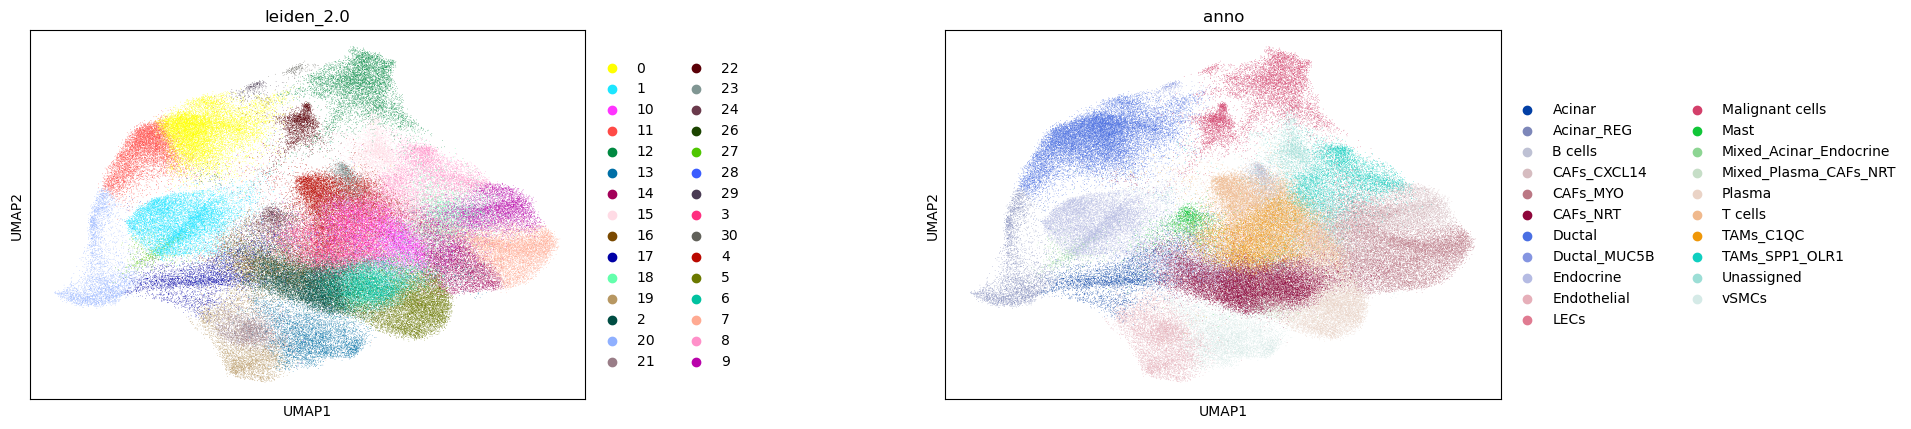

~/.local/lib/python3.9/site-packages/squidpy/pl/_spatial_utils.py:483: FutureWarning: The default value of 'ignore' for the `na_action` parameter in pandas.Categorical.map is deprecated and will be changed to 'None' in a future version. Please set na_action to the desired value to avoid seeing this warning
  color_vector = color_source_vector.map(color_map)
~/.local/lib/python3.9/site-packages/squidpy/pl/_spatial_utils.py:956: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap', 'norm' will be ignored
  _cax = scatter(


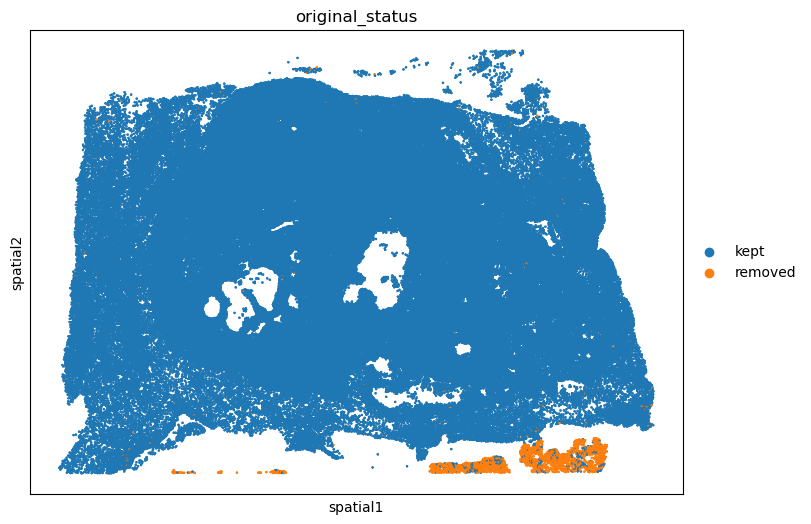

In [6]:
saved = sc.read_h5ad(SAVED_OBJECT, backed="r")

kept_cells = saved.obs_names
missing = kept_cells.difference(adata_all.obs_names)
assert len(missing) == 0, f"{len(missing)} saved cells are not in this run"
is_kept = adata_all.obs_names.isin(kept_cells)
assert list(adata_all.obs_names[is_kept]) == list(kept_cells), "Saved cells are not in the same order"
assert list(saved.var_names) == list(adata_all.var_names), "Saved genes do not match"
assert not set(saved.obs[LEIDEN_KEY].astype(str)) & set(CLUSTERS_REMOVED), "Saved object still holds removed clusters"
print(f"Kept {is_kept.sum()} of {adata_all.n_obs} cells; clusters {CLUSTERS_REMOVED} were removed in the original analysis")

adata_all.obs["original_status"] = pd.Categorical(np.where(is_kept, "kept", "removed"))

adata = adata_all[is_kept, :].copy()
adata.obs[LEIDEN_KEY] = pd.Categorical(saved.obs[LEIDEN_KEY].astype(str).values)
adata.obs["anno"] = pd.Categorical(saved.obs["anno"].astype(str).values)
adata.obsm["X_pca"] = np.asarray(saved.obsm["X_pca"])
adata.obsm["X_umap"] = np.asarray(saved.obsm["X_umap"])
adata.varm["PCs"] = np.asarray(saved.varm["PCs"])
adata.uns["pca"] = {key: np.asarray(value) if not isinstance(value, dict) else dict(value)
                    for key, value in saved.uns["pca"].items()}
saved.file.close()

sc.pl.umap(adata, color=[LEIDEN_KEY, "anno"], wspace=0.5)
sq.pl.spatial_scatter(adata_all, library_id="spatial", shape=None, color=["original_status"], size=2, figsize=(8, 8))

## 4. Gene-set scoring and labels

In [7]:
def assign_labels(data):
    """Score the gene sets, then give each cell its top label if the score reaches the threshold."""
    for cell_type, genes in gene_sets.items():
        sc.tl.score_genes(data, gene_list=genes, score_name=f"{cell_type}_score")

    columns = [f"{cell_type}_score" for cell_type in gene_sets.keys()]
    scores = data.obs[columns]
    threshold = scores.quantile(SCORE_QUANTILE).max()  # the highest SCORE_QUANTILE quantile across all gene sets

    data.obs["max_score"] = scores.max(axis=1)
    labels = scores.idxmax(axis=1).str.replace("_score", "")
    labels[data.obs["max_score"] < threshold] = "Unclassified"
    return threshold, labels, columns


threshold, base_labels, score_columns = assign_labels(adata)
print(f"Threshold: {threshold}")
print(f"Cells below threshold: {int((base_labels == 'Unclassified').sum())} of {adata.n_obs}")


Threshold: 0.3006858227508409
Cells below threshold: 2560 of 154206


In [8]:
def final_labels(labels, anno):
    labels = apply_label_changes(labels.copy(), anno)
    return labels.astype("category")


adata.obs[LABEL_KEY] = final_labels(base_labels, adata.obs["anno"].astype(str))
print(adata.obs[LABEL_KEY].value_counts())

cell_class_threshold
Ductal             19217
Endocrine          15038
Plasma             14900
CAFs_MYO           11635
Acinar             10442
Pericytes           9557
CAFs_CXCL14         9330
Endothelial         6710
Malignant cells     6582
CAFs_NRT            6129
SMCs                5757
TAMs_SPP1           4216
Mast                3507
TAMs_MHC            3324
CD4 T cells         3236
TAMs_C1QC           3095
Ductal MUC5B        2889
Unclassified        2560
B cells             2161
TAMs_OLR1           1842
Migratory DCs       1629
TRCs                1505
DC2                 1410
CD8 T cells         1188
Acinar_REG+          936
LECs                 898
DC1                  874
FRCs                 736
CD4 Treg             677
CD8 TRM              611
NK                   549
Schwann              533
CD4 Tfh              472
Tuft                  61
Name: count, dtype: int64


~/.local/lib/python3.9/site-packages/squidpy/pl/_spatial_utils.py:483: FutureWarning: The default value of 'ignore' for the `na_action` parameter in pandas.Categorical.map is deprecated and will be changed to 'None' in a future version. Please set na_action to the desired value to avoid seeing this warning
  color_vector = color_source_vector.map(color_map)
~/.local/lib/python3.9/site-packages/squidpy/pl/_spatial_utils.py:956: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap', 'norm' will be ignored
  _cax = scatter(


~/.local/lib/python3.9/site-packages/scanpy/plotting/_dotplot.py:168: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  obs_bool.groupby(level=0).sum() / obs_bool.groupby(level=0).count()
~/.local/lib/python3.9/site-packages/scanpy/plotting/_dotplot.py:178: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  dot_color_df = self.obs_tidy.groupby(level=0).mean()
~/.local/lib/python3.9/site-packages/scanpy/tools/_dendrogram.py:133: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt th

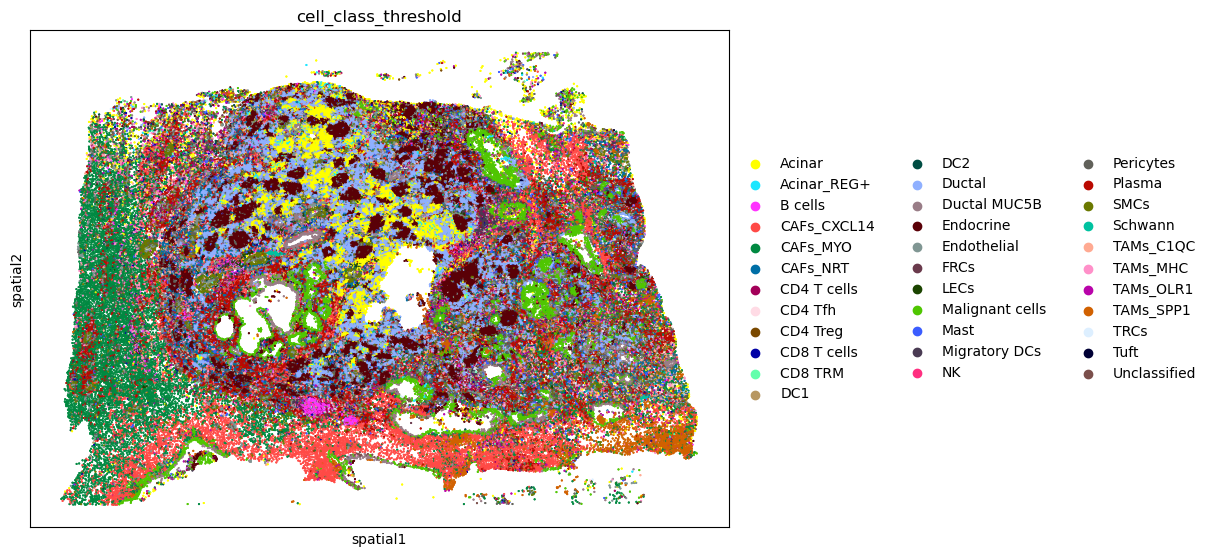

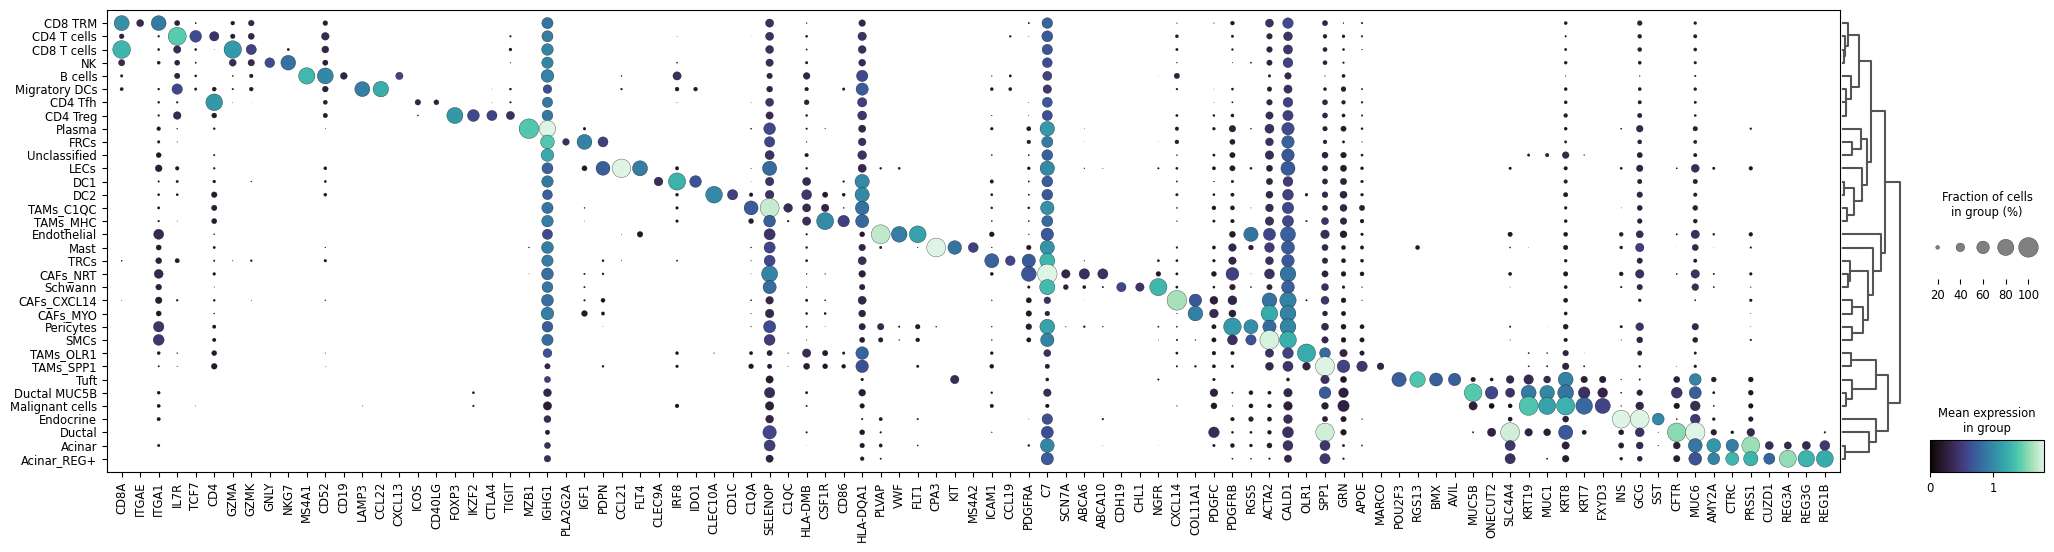

In [9]:
sq.pl.spatial_scatter(adata, shape=None, color=[LABEL_KEY], size=1, library_id="spatial", figsize=(12, 10))

sc.pl.dotplot(adata, var_names=[g for g in dict.fromkeys(label_markers) if g in adata.var_names], groupby=LABEL_KEY,
              figsize=(25, 6), vmax=1.8, vmin=0, dot_min=0.1, cmap="mako", dendrogram=True)

## 5. Nhood enrichment

  0%|          | 0/1000 [00:00<?, ?/s]

~/miniconda3/envs/xenium.squidpy/lib/python3.9/site-packages/anndata/_core/anndata.py:430: FutureWarning: The dtype argument is deprecated and will be removed in late 2024.
  warnings.warn(
~/.local/lib/python3.9/site-packages/squidpy/pl/_utils.py:556: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  row_labels = adata.obs[key][row_order]


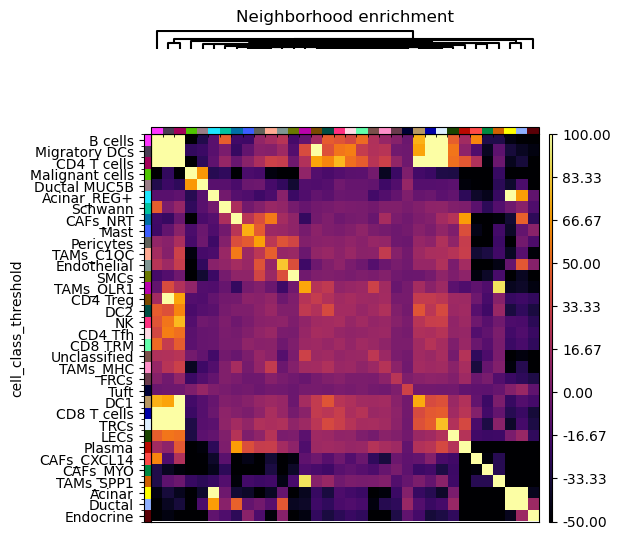

In [10]:
sq.gr.spatial_neighbors(adata, coord_type="generic", spatial_key="spatial", radius=RADIUS_UM)
sq.gr.nhood_enrichment(adata, cluster_key=LABEL_KEY, seed=NHOOD_SEED)
sq.pl.nhood_enrichment(adata, cluster_key=LABEL_KEY, method="average", cmap="inferno",
                       vmin=-50, vmax=100, figsize=(5, 5))

## 6. Robustness check: recalculated PCA

This recalculates PCA and clusters on all cells that passed QC, then removes any recalculated cluster in which at least `REMOVAL_SHARE` of the cells were originally removed, and repeats scoring, labels and Nhood enrichment. The rule refers to the original removals, so this tests stability; it isn't an independent way of finding the cells to remove.

In [11]:
def compare_nhood(first, second):
    """Correlation and largest difference of Nhood z-scores, across the labels in both objects."""
    key = f"{LABEL_KEY}_nhood_enrichment"
    cats_first = list(first.obs[LABEL_KEY].astype("category").cat.categories)
    cats_second = list(second.obs[LABEL_KEY].astype("category").cat.categories)
    shared = [c for c in cats_first if c in cats_second]
    z_first = pd.DataFrame(first.uns[key]["zscore"], index=cats_first, columns=cats_first).loc[shared, shared].values
    z_second = pd.DataFrame(second.uns[key]["zscore"], index=cats_second, columns=cats_second).loc[shared, shared].values
    valid = ~(np.isnan(z_first) | np.isnan(z_second))
    labels_differ = sorted(set(cats_first) ^ set(cats_second))
    return np.corrcoef(z_first[valid], z_second[valid])[0, 1], np.abs(z_first[valid] - z_second[valid]).max(), labels_differ


sc.pp.pca(adata_all, random_state=PCA_SEED)
sc.pp.neighbors(adata_all, n_neighbors=N_NEIGHBORS, random_state=GLOBAL_SEED)
sc.tl.leiden(adata_all, resolution=LEIDEN_RESOLUTION, key_added="leiden_recalculated_pca", random_state=GLOBAL_SEED)

share_removed = adata_all.obs.groupby("leiden_recalculated_pca", observed=True)["original_status"].apply(
    lambda status: (status == "removed").mean()
)
clusters_excluded = list(share_removed[share_removed >= REMOVAL_SHARE].index)
print("Recalculated clusters removed by the rule:", clusters_excluded)

alternative = adata_all[~adata_all.obs["leiden_recalculated_pca"].isin(clusters_excluded), :].copy()
# Cells that were originally removed have no original annotation
alternative.obs["anno"] = adata.obs["anno"].astype(str).reindex(alternative.obs_names).fillna("Originally removed").values
_, alternative_labels, _ = assign_labels(alternative)
alternative.obs[LABEL_KEY] = final_labels(alternative_labels, alternative.obs["anno"].astype(str))
sq.gr.spatial_neighbors(alternative, coord_type="generic", spatial_key="spatial", radius=RADIUS_UM)
sq.gr.nhood_enrichment(alternative, cluster_key=LABEL_KEY, seed=NHOOD_SEED)

# Keep the per-cell labels for testing niche stability in Stage 2
pd.DataFrame({
    "cell_index": alternative.obs_names,
    "x_centroid": alternative.obsm["spatial"][:, 0],
    "y_centroid": alternative.obsm["spatial"][:, 1],
    LABEL_KEY: alternative.obs[LABEL_KEY].astype(str).values,
}).to_csv(os.path.join(OUTPUT_DIR, "recalculated_labels.csv.gz"), index=False)

shared_cells = adata.obs_names.intersection(alternative.obs_names)
same_label = (adata.obs.loc[shared_cells, LABEL_KEY].astype(str) == alternative.obs.loc[shared_cells, LABEL_KEY].astype(str)).mean()
z_correlation, z_difference, labels_differ = compare_nhood(adata, alternative)

robustness = pd.DataFrame(
    [
        ("Same label", f"{same_label:.4%}"),
        ("Nhood z-score correlation", f"{z_correlation:.4f}"),
        ("Nhood z-score, max difference", f"{z_difference:.3g}"),
        ("Labels only in one result", labels_differ),
        ("Cells kept, original", adata.n_obs),
        ("Cells kept, rule-based removal", alternative.n_obs),
        ("Adjusted Rand index, kept cells", f"{adjusted_rand_score(adata.obs[LEIDEN_KEY].astype(str), adata_all.obs.loc[adata.obs_names, 'leiden_recalculated_pca'].astype(str)):.4f}"),
    ],
    columns=["measure", "value"],
)
robustness.to_csv(os.path.join(OUTPUT_DIR, "robustness_summary.tsv"), sep="\t", index=False)
display(robustness)

Recalculated clusters removed by the rule: ['26']


  0%|          | 0/1000 [00:00<?, ?/s]

,measure,value
0,Same label,99.1225%
1,Nhood z-score correlation,0.9991
2,"Nhood z-score, max difference",101
3,Labels only in one result,[]
4,"Cells kept, original",154206
5,"Cells kept, rule-based removal",154105
6,"Adjusted Rand index, kept cells",0.7488


## 7. Save outputs

In [12]:
adata.write_h5ad(os.path.join(OUTPUT_DIR, f"{SAMPLE}.h5ad"))

# Values in this file are adata.X (log-normalised), not raw counts
metadata = pd.DataFrame({
    "x_location": adata.obs["x_centroid"].values,
    "y_location": adata.obs["y_centroid"].values,
    "cluster_based_annotation": adata.obs["anno"].values,
    "gene_set_scoring_annotation": adata.obs[LABEL_KEY].values,
    "transcript_counts": adata.obs["transcript_counts"].values,
}, index=adata.obs_names)
expression = pd.DataFrame(adata.X.toarray(), index=adata.obs_names, columns=adata.var_names)
pd.concat([metadata, expression], axis=1).to_csv(os.path.join(OUTPUT_DIR, f"{SAMPLE}.csv"), index=False)
del expression

## 8. Check against the saved object

In a passing run, `Same label` is 100%, the score difference is 0 and the Nhood correlation is 1.

In [14]:
reference = sc.read_h5ad(SAVED_OBJECT, backed="r")
assert list(adata.obs_names) == list(reference.obs_names), "Cells differ from the saved object"

same_label = (adata.obs[LABEL_KEY].astype(str).values == reference.obs[LABEL_KEY].astype(str).values).mean()
score_difference = np.abs(adata.obs[score_columns].values - reference.obs[score_columns].values).max()

key = f"{LABEL_KEY}_nhood_enrichment"
categories = list(adata.obs[LABEL_KEY].cat.categories)
reference_categories = list(reference.obs[LABEL_KEY].astype("category").cat.categories)
assert set(categories) == set(reference_categories), f"Labels differ: {sorted(set(categories) ^ set(reference_categories))}"
z_new = adata.uns[key]["zscore"]
z_reference = pd.DataFrame(reference.uns[key]["zscore"], index=reference_categories, columns=reference_categories).loc[categories, categories].values
valid = ~(np.isnan(z_new) | np.isnan(z_reference))

check = [
    ("Cells", adata.n_obs),
    ("Same label", f"{same_label:.4%}"),
    ("Gene-set scores, max difference", f"{score_difference:.3g}"),
    ("Nhood z-score correlation", f"{np.corrcoef(z_new[valid], z_reference[valid])[0, 1]:.4f}"),
    ("Nhood z-score, max difference", f"{np.abs(z_new[valid] - z_reference[valid]).max():.3g}"),
]
reference.file.close()

if os.path.exists(COUNTS_CSV):
    csv_labels = pd.read_csv(COUNTS_CSV, usecols=["gene_set_scoring"])["gene_set_scoring"]
    if len(csv_labels) == adata.n_obs:
        check.append(("Same label as counts CSV", f"{(csv_labels.astype(str).values == adata.obs[LABEL_KEY].astype(str).values).mean():.4%}"))

check = pd.DataFrame(check, columns=["measure", "value"])
check.to_csv(os.path.join(OUTPUT_DIR, "stage1_check.tsv"), sep="\t", index=False)
display(check)

,measure,value
0,Cells,154206
1,Same label,100.0000%
2,"Gene-set scores, max difference",0
3,Nhood z-score correlation,1.0000
4,"Nhood z-score, max difference",0
5,Same label as counts CSV,100.0000%
